# Inter-Area Oscillations and the PSS: RAMSES on the Kundur Two-Area System

This tutorial uses the [STEPSS](https://stepss.sps-lab.org) platform, through the
[stepss](https://stepss.sps-lab.org/python/) Python package, to reproduce the textbook
result this test system exists for: **a power system stabilizer (PSS) is what damps the
inter-area mode.**

We run the *same* disturbance twice, changing exactly one number in the data:

1. with the PSS gain at its design value (`dyn.dat`, $K_{STAB} = 20$), and
2. with the PSS switched off (`dyn_noPSS.dat`, $K_{STAB} = 0$),

then compare the rotor-angle swing between the two areas. In the first case the
oscillation decays; in the second it grows until the machines pull out of step and
RAMSES stops the run.

**Installation** (needed only if you are not on the course JupyterHub):

```bash
pip install jupyter ipython stepss
```

On Linux the engine additionally needs `libopenblas0 libgfortran5 libgomp1`
(see the [installation guide](https://stepss.sps-lab.org/python/installation/)).

## The two-area system

Kundur's two-area system (*Power System Stability and Control*, McGraw-Hill 1994,
Example 12.6) is the standard small benchmark for **inter-area oscillations**. It is
deliberately symmetric:

- **11 buses at 60 Hz.** Four 20-kV generator buses (1 to 4), stepped up to a 230-kV
  transmission ring (buses 5 to 11).
- **Four identical 900-MVA machines**, `G1` and `G2` in area 1, `G3` and `G4` in area 2,
  each with an `exc_kundur` AVR plus PSS and a `THERMAL_GENERIC1` governor.
- **Two load centres**, at bus 7 (967 MW) and bus 9 (1767 MW), each with a capacitor bank
  (200 and 350 Mvar) that props the local voltage up.
- **A weak tie**: buses 7 and 8 and buses 9 and 8 are joined by *double* circuits of
  fairly high impedance, so area 1 exports about 400 MW to area 2 across a long,
  electrically weak corridor.

That last point is the whole design. Two stiff areas joined by a weak tie oscillate
against each other at a low frequency, typically 0.2 to 0.8 Hz, with the machines of one
area swinging coherently against those of the other. High-gain AVRs, which every machine
here has ($K_A = 200$), make that mode *less* damped, and a PSS is the standard cure.

## The data files, and who reads what

| File | Contents |
|------|----------|
| `lf.dat` | Network **and** the solved operating point: 11 buses, 4 step-up transformers, 8 lines, 4 `GENER` records, the slack, and the `LFRESV` bus voltages |
| `dyn.dat` | Dynamic models: the four `SYNC_MACH` records with their `exc_kundur` AVR/PSS and `THERMAL_GENERIC1` governor, the two voltage-dependent loads (`vfd_load`), the two shunt capacitors |
| `dyn_noPSS.dat` | Identical to `dyn.dat`, with the PSS gain $K_{STAB}$ set from 20.0 to 0.0 on all four machines |
| `disturb.dst` | The disturbance: a +0.5 pu step on the active power of load `L9` at $t = 1$ s, 60 s horizon |
| `obs.dat` | Which variables to record (wildcards, so everything) |
| `solveroptions.dat` | Solver settings, plus the two monitoring controllers described below |

Note that `lf.dat` carries the `LFRESV` records itself, so this case needs no separate
power-flow step: unlike the Nordic system, the solved operating point travels with the
network file and RAMSES can initialise straight from it.

Two records at the bottom of `solveroptions.dat` matter later:

```
DCTL SIM_MINMAXVOLT Voltages 0.6 1.4 3 0 ;
DCTL SIM_MINMAXSPEED Speeds  0.9 1.05 2 0 ;
```

These are **watchdogs**, not physical models. They abort the simulation if any bus voltage
leaves [0.6, 1.4] pu or any machine speed leaves [0.9, 1.05] pu. In the unstable run below
this is what stops the integration, and the abort is the *result*, not a failure of the
tool.

In [1]:
import glob
import os

import numpy as np
import stepss
from stepss import ssa

print('stepss', stepss.__version__)

stepss 3.81.2


## The operating point, on the one-line diagram

`kundur.svg` is a diagram *template*: the `%A`-`%U` codes in its text elements are
placeholders that HELIOS replaces with solved values. Solving `lf.dat` and rendering the
template gives the operating point every run below starts from, with voltage magnitudes in
red, phase angles in gold, and active and reactive flows in blue and green. Branch flows are
given at the bus end shown, positive out of the bus into the branch.

power flow converged: True in 1 iteration(s)


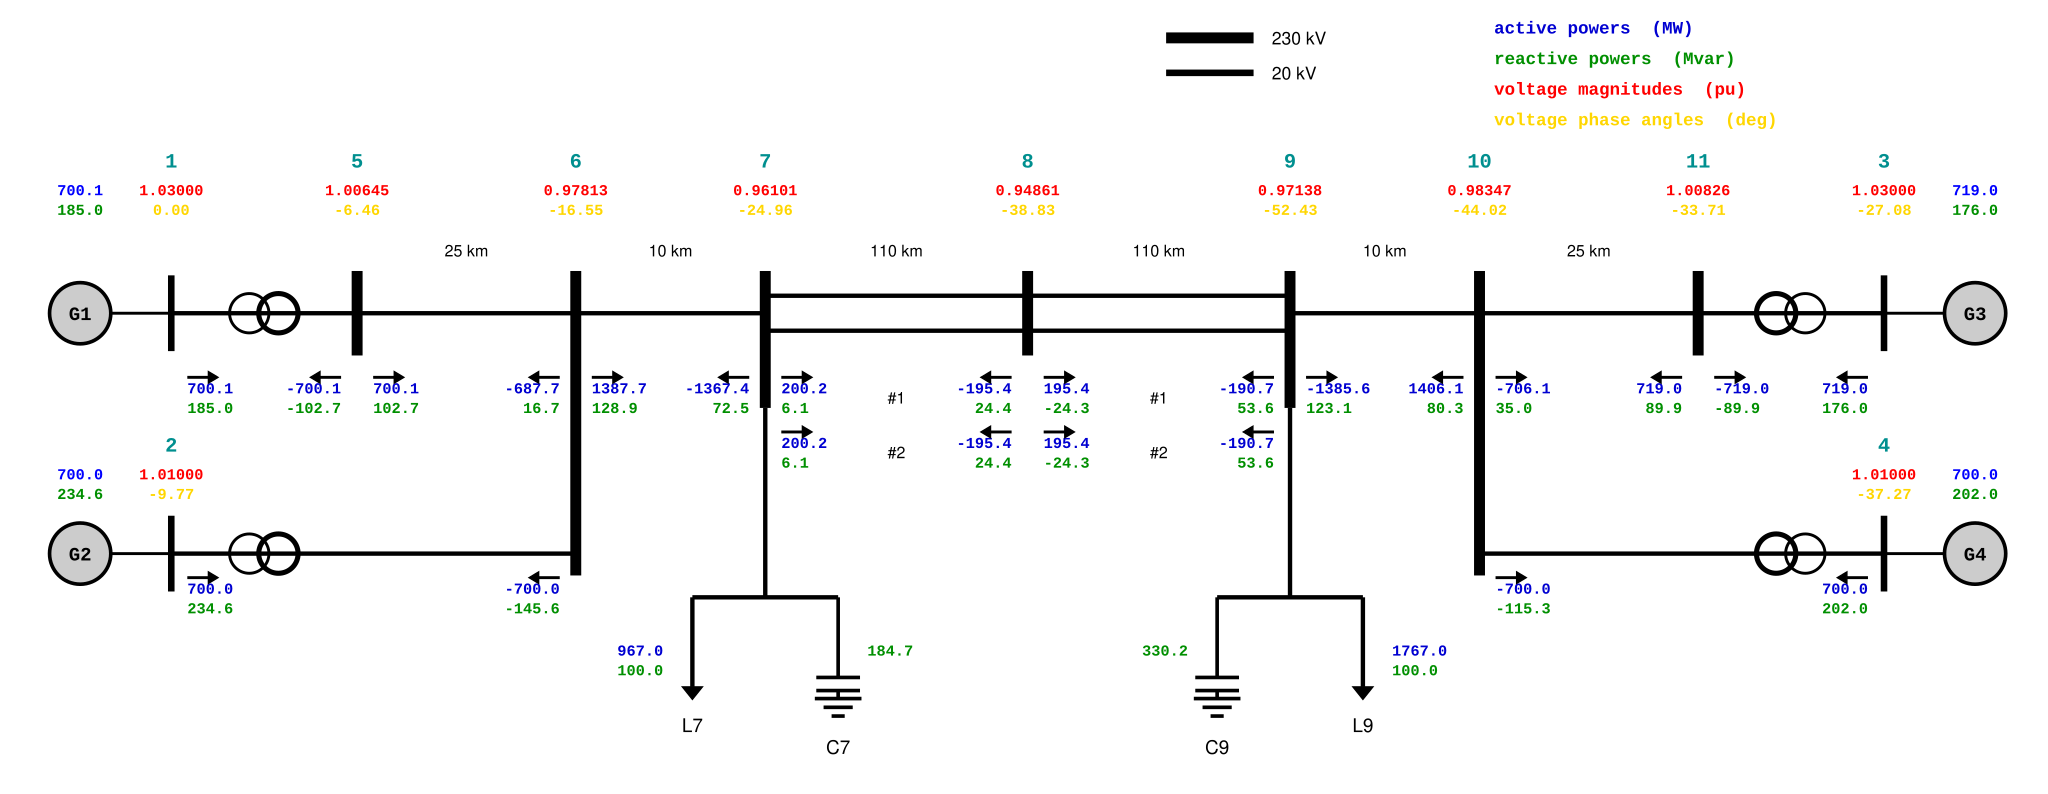

In [2]:
from IPython.display import SVG, display
from stepss.helios import HeliosSession

with HeliosSession() as pf:
    pf.load_file('lf.dat')
    print(f'power flow converged: {pf.solve()} in {pf.iterations} iteration(s)')
    pf.write_diagram('kundur.svg', 'kundur_solved.svg')

display(SVG('kundur_solved.svg'))

## The disturbance

Small enough to stay in the linear regime, large enough to excite the mode:

In [3]:
print(open('disturb.dst').read())

  0.000 CONTINUE SOLVER BD 0.01 0.0001 0. ALL
  1.000 CHGPRM INJ L9 Po +0.5 0
 60.000 STOP



`CHGPRM INJ L9 Po +0.5 0` raises the active-power set-point of the load at bus 9, in the
importing area, by 0.5 pu on the injector base. Area 1 must ship the extra power across
the weak tie, which is exactly the path the inter-area mode lives on.

## Part 1: the base case, PSS in service

A RAMSES case is a `cfg` object listing the input files and where the outputs go.

In [4]:
# clear outputs of any previous run
for f in glob.glob('*.trj') + glob.glob('*.trace'):
    os.remove(f)


def run_case(dyn_file, tag):
    """Run the load step with the given dynamic data file.

    Returns (extractor, completed) where `completed` is False when a monitoring
    DCTL aborted the integration before the STOP event of the scenario.
    """
    case = stepss.cfg()
    case.addData('lf.dat')             # network + solved operating point
    case.addData(dyn_file)             # dynamic models
    case.addData('solveroptions.dat')  # solver settings + monitoring DCTLs
    case.addDst('disturb.dst')         # +0.5 pu step on L9 at t = 1 s
    case.addObs('obs.dat')
    case.addTrj(f'output_{tag}.trj')
    case.addOut(f'output_{tag}.trace')
    case.addInit(f'init_{tag}.trace')

    completed = True
    try:
        stepss.sim().execSim(case)
    except Exception as err:
        completed = False
        print(f'[{tag}] integration stopped early: {str(err).split("Last message was:")[-1].strip()}')
    return stepss.extractor(case.getTrj()), completed


ext_pss, done_pss = run_case('dyn.dat', 'pss')
print('PSS case completed:', done_pss)

PSS case completed: True


### Reading rotor angles in this case

`solveroptions.dat` sets `$OMEGA_REF SYN`, so rotor angles are measured against a frame
turning at *constant nominal speed*, not against the centre of inertia. After the load
step the governors settle the system slightly below 60 Hz, so **every** machine angle then
drifts downwards together at the same rate. That common drift is not an oscillation:

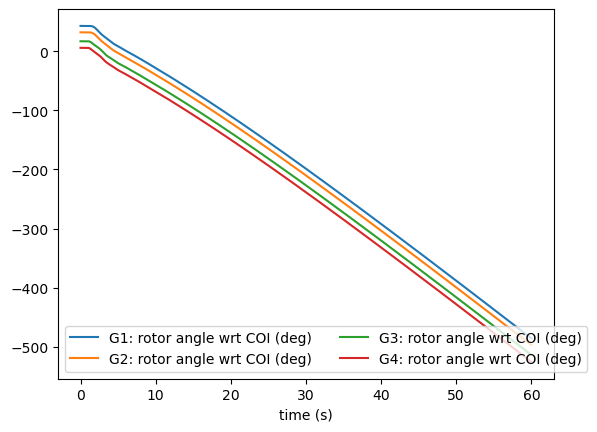

settled machine speed: 0.99955 pu  ->  59.973 Hz


In [5]:
ang = {g: ext_pss.getSync(g).A for g in ('G1', 'G2', 'G3', 'G4')}
stepss.curplot(list(ang.values()))

speed = ext_pss.getSync('G1').S.value[-1]
print(f'settled machine speed: {speed:.5f} pu  ->  {60.0 * speed:.3f} Hz')

The information is in the **differences**. The inter-area mode is the swing of area 1
against area 2, so we take the angle of a machine in each area and subtract:

$$\delta_{\text{inter-area}} = \delta_{G1} - \delta_{G3}$$

The common drift cancels exactly, leaving the oscillation.

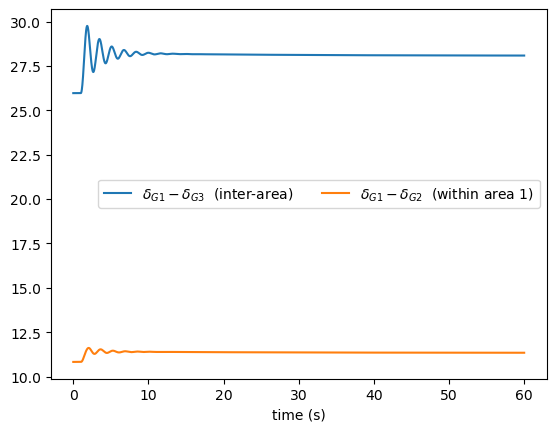

In [6]:
t = ang['G1'].time
d_pss = ang['G1'].value - ang['G3'].value
d_local = ang['G1'].value - ang['G2'].value

stepss.curplot([stepss.cur(t, d_pss, r'$\delta_{G1}-\delta_{G3}$  (inter-area)'),
                stepss.cur(t, d_local, r'$\delta_{G1}-\delta_{G2}$  (within area 1)')])

Two modes are visible and they are not the same. The **local** mode, one machine against
its neighbour in the same area, is fast and dies almost immediately. The **inter-area**
mode is slower and lives much longer, and it is the one the PSS is tuned for.

We can read its frequency and damping straight off the decaying envelope, by fitting a
straight line to the logarithm of the successive peak amplitudes:

In [7]:
def mode_estimate(time, signal, t_from=1.5, t_to=25.0):
    """Frequency and damping ratio of the dominant mode, from successive peaks."""
    m = (time >= t_from) & (time <= t_to)
    tt, xx = time[m], signal[m] - signal[m][-1]
    # local maxima of the deviation from the settling value
    peaks = [i for i in range(1, len(xx) - 1) if xx[i] > xx[i - 1] and xx[i] >= xx[i + 1] and xx[i] > 0]
    if len(peaks) < 3:
        return None
    tp, xp = tt[peaks], xx[peaks]
    period = np.mean(np.diff(tp))
    # logarithmic decrement over the peak train
    slope = np.polyfit(tp, np.log(xp), 1)[0]
    sigma = -slope
    omega_d = 2 * np.pi / period
    zeta = sigma / np.hypot(sigma, omega_d)
    return dict(f_hz=1.0 / period, zeta=zeta, n_peaks=len(peaks))


est = mode_estimate(t, d_pss)
print(f"inter-area mode with PSS: {est['f_hz']:.3f} Hz, "
      f"damping ratio {est['zeta'] * 100:.1f} % (from {est['n_peaks']} peaks)")

inter-area mode with PSS: 0.627 Hz, damping ratio 6.1 % (from 12 peaks)


Around 0.6 Hz, in the middle of the 0.2 to 0.8 Hz band inter-area modes occupy, and damped
at roughly 6 %. Grid codes commonly ask for at least 3 to 5 % on such a mode, so on this
estimate the tuned PSS puts the system just the right side of the line.

Treat that damping figure with care: it is read off a decaying time response, and a mode
this close to a threshold is exactly the case where the estimate is not good enough to
decide on. **Part 3 computes the same mode as an eigenvalue** and gets 10.9 %, not 6 %, so
the real margin is far wider than this fit suggests.

## Part 2: the same disturbance with the PSS disabled

`dyn_noPSS.dat` differs from `dyn.dat` in four numbers, one per machine: the PSS gain
$K_{STAB}$ in the `exc_kundur` record, 20.0 becomes 0.0. Everything else, including the
AVR gain of 200, is untouched.

In [8]:
import difflib
diff = difflib.unified_diff(open('dyn.dat').readlines(), open('dyn_noPSS.dat').readlines(),
                            'dyn.dat', 'dyn_noPSS.dat', n=0)
for line in diff:
    if line.startswith(('---', '+++')) or (line[:1] in '-+' and line[1:].strip()):
        print(line.rstrip())

--- dyn.dat
+++ dyn_noPSS.dat
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4


In [9]:
ext_nopss, done_nopss = run_case('dyn_noPSS.dat', 'nopss')
print('no-PSS case completed:', done_nopss)

[nopss] integration stopped early: ERROR CALL FROM DCTL sim_minmaxvolt Voltages t =   36.5002         Voltage out of bounds at bus 8 :  0.60
no-PSS case completed: False


The run did **not** reach the 60-s `STOP` of the scenario. The `SIM_MINMAXVOLT` watchdog
fired: a bus voltage fell through 0.6 pu, which is what happens when machines lose
synchronism and the voltage collapses at the electrical centre of the swing. RAMSES stops
there rather than integrating a meaningless post-pole-slip trajectory, and everything
recorded up to that instant is still in the trajectory file.

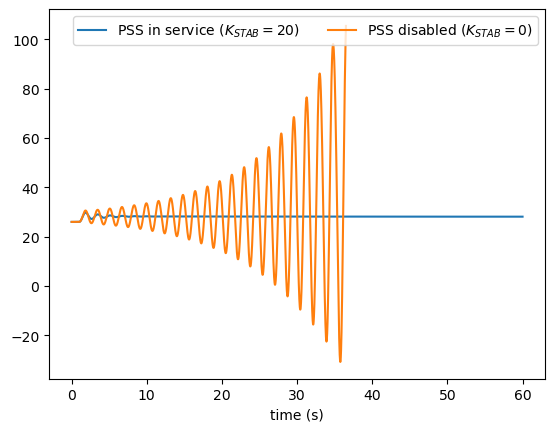

run aborted at t                :   36.5 s
angle difference span, PSS      :    3.8 deg
angle difference span, no PSS   :  136.1 deg
final angle difference, no PSS  :  105.4 deg  (started at 26.0 deg)


In [10]:
t_np = ext_nopss.getSync('G1').A.time
d_nopss = ext_nopss.getSync('G1').A.value - ext_nopss.getSync('G3').A.value

stepss.curplot([stepss.cur(t, d_pss, 'PSS in service ($K_{STAB}=20$)'),
                stepss.cur(t_np, d_nopss, 'PSS disabled ($K_{STAB}=0$)')])

print(f'run aborted at t                : {t_np[-1]:6.1f} s')
print(f'angle difference span, PSS      : {np.ptp(d_pss):6.1f} deg')
print(f'angle difference span, no PSS   : {np.ptp(d_nopss):6.1f} deg')
print(f'final angle difference, no PSS  : {d_nopss[-1]:6.1f} deg  (started at {d_nopss[0]:.1f} deg)')

The contrast is the whole point of the test system. The same 0.5 pu load step, on the same
network, at the same operating point: with the PSS the swing peaks at a few degrees and is
gone within 20 s; without it the swing grows monotonically until the two areas are more
than 100 degrees apart and the run is stopped.

Watch the same instability in the two other quantities an operator would see, the machine
speeds and the tie-corridor voltage:

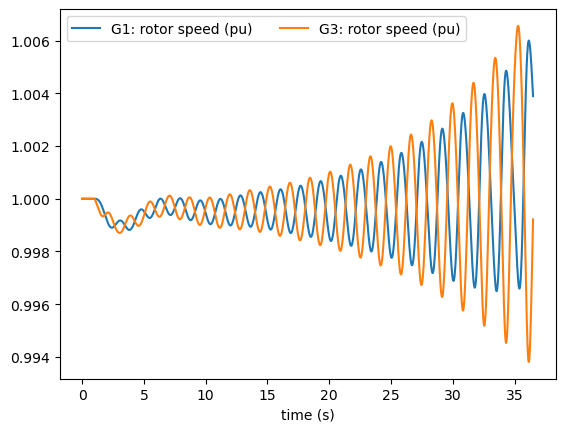

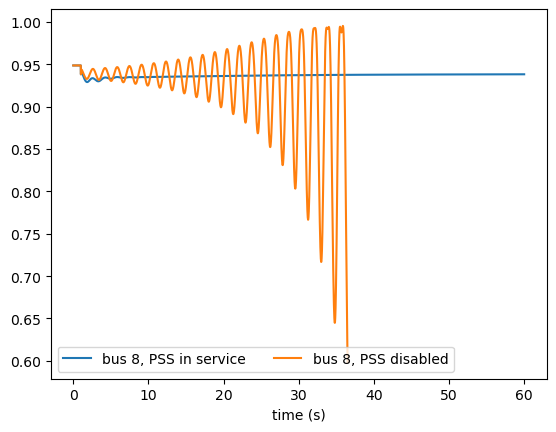

In [11]:
stepss.curplot([ext_nopss.getSync('G1').S, ext_nopss.getSync('G3').S])

v_pss, v_nopss = ext_pss.getBus('8').mag, ext_nopss.getBus('8').mag
stepss.curplot([stepss.cur(v_pss.time, v_pss.value, 'bus 8, PSS in service'),
                stepss.cur(v_nopss.time, v_nopss.value, 'bus 8, PSS disabled')])

Bus 8 is the electrical midpoint of the tie, and it is the bus that collapses: as the two
areas separate in angle, the voltage at the point between them is squeezed towards zero.
That is why the watchdog placed the floor there rather than at a generator terminal.

In [12]:
# Key outcomes, side by side.
print(f'{"":34}{"PSS":>12} {"no PSS":>12}')
rows = [
    ('simulated to (s)',        lambda e: e.getSync('G1').A.time[-1]),
    ('swing span, delta G1-G3 (deg)', lambda e: np.ptp(e.getSync('G1').A.value - e.getSync('G3').A.value)),
    ('final delta G1-G3 (deg)',  lambda e: (e.getSync('G1').A.value - e.getSync('G3').A.value)[-1]),
    ('lowest V at bus 8 (pu)',   lambda e: e.getBus('8').mag.value.min()),
    ('lowest machine speed (pu)', lambda e: min(e.getSync(g).S.value.min() for g in ['G1', 'G2', 'G3', 'G4'])),
]
for label, fn in rows:
    print(f'{label:34}{fn(ext_pss):12.3f} {fn(ext_nopss):12.3f}')

                                           PSS       no PSS
simulated to (s)                        60.000       36.500
swing span, delta G1-G3 (deg)            3.788      136.129
final delta G1-G3 (deg)                 28.087      105.369
lowest V at bus 8 (pu)                   0.929        0.599
lowest machine speed (pu)                0.999        0.994


## Part 3: the same question asked directly, as an eigenvalue problem

Everything so far has been read off a time response. That works, but it is indirect:
`mode_estimate` fitted a straight line to the logarithm of successive peaks, which needs
a disturbance big enough to excite the mode, a window clear of the faster local mode, and
enough peaks before the signal settles. It also gives one number for whichever mode
happens to dominate the window, and says nothing about the others.

**Small-signal analysis asks the machine directly.** RAMSES linearises the whole system
about its operating point and returns the eigenvalues $\lambda = \sigma \pm j\omega_d$ of
the state matrix. Each conjugate pair is one mode, with

$$f = \frac{\omega_d}{2\pi}, \qquad \zeta = \frac{-\sigma}{\sqrt{\sigma^2 + \omega_d^2}}$$

and the sign of $\sigma$ decides stability outright: a mode with $\text{Re}(\lambda) > 0$
grows. No disturbance is needed, no fitting, and every mode comes back at once, not just
the one the load step happened to excite.

The analysis is triggered by the `EIG` disturbance, which takes a basename and nothing
else, and writes three files: the modes, the participation factors, and the mode shapes.

### The scenario the analysis runs under

`EIG` linearises about whatever state the system is in at the instant it fires, so it has
to fire before anything has happened. Running it against `disturb.dst` would describe a
point mid-swing rather than the operating point, and in this case it does not get that
far: the engine aborts on the load step that follows. So the analysis needs a scenario of
its own, with no events in it but the analysis itself.

`ssa.run()` writes that scenario itself, whenever the case it is given carries no
disturbance file of its own, which is also what the STEPSS GUI does: press **Run
analysis** on the Analysis tab and it writes the same quiet scenario for you. Below, the
case is built with no `addDst` call at all, which is worth showing: the operating point
lives in `lf.dat`, the same one Parts 1 and 2 initialise from, so nothing has to be copied
out of `disturb.dst` by hand to reach it.

In [13]:
def run_ssa(dyn_file, workdir):
    """Linearise about the operating point with the given dynamic data.

    No addDst: ssa.run() writes a disturbance file with no events of its own
    when the case carries none, which is exactly the quiet scenario EIG needs,
    since it linearises about whatever state the system is in when it fires.
    Each variant gets its own working directory, since both runs share the
    basename 'eig' and would otherwise overwrite each other's results.
    """
    case = stepss.cfg()
    case.addData('lf.dat')             # network + solved operating point
    case.addData(dyn_file)             # dynamic models, PSS gain differs
    case.addData('solveroptions.dat')  # solver settings
    case.addObs('obs.dat')
    case.addTrj('eig.trj')
    return ssa.run(case, basename='eig', workdir=workdir)


res_pss = run_ssa('dyn.dat', 'ssa_pss')
res_nopss = run_ssa('dyn_noPSS.dat', 'ssa_nopss')
print(f'{len(res_pss.modes)} modes returned per run')

70 modes returned per run


### The inter-area mode, exactly

Part 1 estimated this mode from the decaying envelope. Here it is as an eigenvalue, next
to that estimate.

In [14]:
ia_pss = res_pss.electromechanical(0.4, 0.9)      # the inter-area band
ia_nopss = res_nopss.electromechanical(0.4, 0.9)

print('WITH PSS')
ia_pss.table()
print('\nWITHOUT PSS')
ia_nopss.table()

print(f"\nenvelope fit, Part 1  {est['f_hz']:.4f} Hz, zeta {est['zeta']:+.4f}")

WITH PSS
  mode   f [Hz]    zeta        lambda                     simple
  35     0.6237    +0.1087     -0.4287 +3.9190j           yes

WITHOUT PSS
  mode   f [Hz]    zeta        lambda                     simple
  31     0.6246    -0.0233     +0.0914 +3.9245j           yes

envelope fit, Part 1  0.6275 Hz, zeta +0.0609


The two agree on **frequency** to better than a percent, 0.6275 Hz against 0.6237 Hz. On
**damping** they do not: the envelope fit says 6.1 %, the eigenvalue says 10.9 %, so the
fit understates the damping by nearly half.

The eigenvalue is the one to believe, and the disagreement is a property of the estimate
rather than of the engine. `mode_estimate` assumes the signal is a single decaying
sinusoid, and over its 1.5 to 25 s window it is not: the local mode is still present early
on, the peak train is only a few peaks long, and the settling value it subtracts is taken
from the end of that window rather than from the true steady state. Each of those biases
the logarithmic decrement, and the result is a damping ratio that is the right order and
the wrong number.

That matters for the conclusion Part 1 drew from it. At 6 % this mode looked as though it
sat just the right side of a 3 to 5 % planning criterion; at 10.9 % it clears that
criterion comfortably. Reading damping off a decaying response is fine for seeing whether
a mode decays, and unreliable for deciding how close it is to a limit.

The second row is the one Part 2 spent a 60-second simulation demonstrating:
$\zeta = -0.023$, a **negative** damping ratio, so the 0.62 Hz oscillation between the two
areas grows. The eigenvalue says so directly, from the operating point alone, without
waiting for the machines to pull out of step.

Note also that the frequency barely moves, 0.624 Hz against 0.625 Hz. The stabiliser is
not retuning the oscillation, it is adding damping to it.

### Every swing mode, not just the excited one

The load step in Parts 1 and 2 happened to excite the inter-area mode. The eigenvalues
come back all at once, so the local modes are here too, without a second run.

`electromechanical()` narrows the full mode set to the rotor-swing band, 0.1 to 2.5 Hz.
That band still holds a cluster of heavily damped, non-oscillatory poles, one of them out
at Re = -24. `dominant()` cuts those on the real part instead of the damping ratio, the
same control the desktop application's Analysis tab drives with its "real part above"
field. Its own default is -1.0, but that is too tight here: with the PSS in service the
two local modes sit at Re = -2.35 and -2.43, damped at about 29 % and exactly the modes
worth showing, and a -1.0 limit drops both of them from the table below. -3.0 keeps every
genuine swing mode in both runs and still excludes the heavily damped cluster near 0.1 Hz.

In [15]:
dom_pss = res_pss.electromechanical().dominant(-3.0)
dom_nopss = res_nopss.electromechanical().dominant(-3.0)

print('WITH PSS')
dom_pss.table()
print('\nWITHOUT PSS')
dom_nopss.table()

WITH PSS
  mode   f [Hz]    zeta        lambda                     simple
  45     0.1486    +0.7046     -0.9269 +0.9336j           yes
  35     0.6237    +0.1087     -0.4287 +3.9190j           yes
  27     1.2424    +0.2880     -2.3481 +7.8065j           yes
  25     1.2950    +0.2865     -2.4331 +8.1365j           yes

WITHOUT PSS
  mode   f [Hz]    zeta        lambda                     simple
  41     0.1342    +0.3528     -0.3179 +0.8433j           yes
  31     0.6246    -0.0233     +0.0914 +3.9245j           yes
  25     1.0850    +0.0990     -0.6781 +6.8172j           yes
  23     1.1161    +0.0966     -0.6809 +7.0128j           yes



### The modes on the complex plane

`splane()` draws the same picture the STEPSS desktop application draws on its own
**Analysis** tab, so a figure from this notebook and a screenshot from the application
read the same way:

- a **crimson vertical line at $\text{Re}(\lambda) = 0$** is the stability boundary;
  everything left of it decays, everything right of it grows;
- one **hollow circle per mode**, labelled with its frequency and drawn crimson when
  that mode is unstable;
- a **dashed grey ray** from the origin at constant damping, here $\zeta = 0.05$, the
  usual planning criterion. A mode left of the ray meets it; a mode between the ray and
  the boundary is stable but poorly damped.

Each call fits its own window to the modes it is given, so compare the two figures by
their axis numbers rather than by where a circle sits on the page.

s-plane drawn without interaction: this backend has no window to update. In a script, switch to an interactive backend before plotting; in a notebook, run %matplotlib widget first. Either gives click-to-select and drag-to-zoom.
s-plane drawn without interaction: this backend has no window to update. In a script, switch to an interactive backend before plotting; in a notebook, run %matplotlib widget first. Either gives click-to-select and drag-to-zoom.


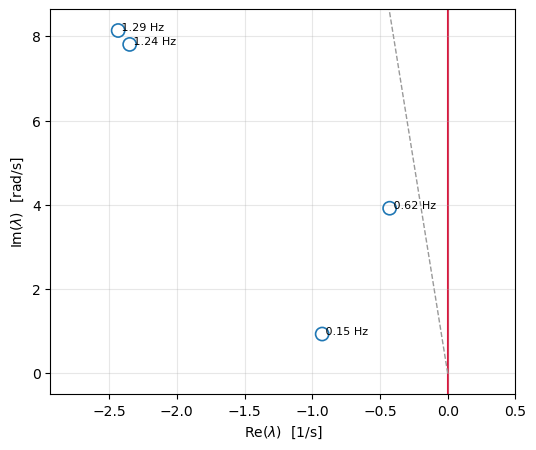

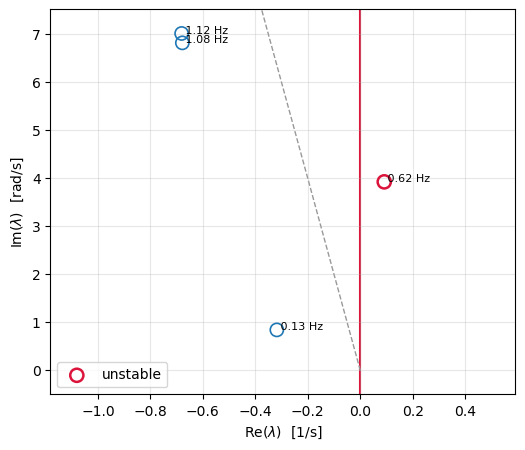

In [16]:
dom_pss.splane()     # PSS in service
dom_nopss.splane();  # PSS disabled

The whole result of Parts 1 and 2 is in the difference between these two panels. With the
stabiliser in service every swing mode sits left of the boundary, and the inter-area mode
at 0.62 Hz is clear of the $\zeta = 0.05$ ray with room to spare. With it disabled, that
same mode has crossed to the right of the boundary and is drawn crimson: it grows, which
is exactly the divergence the 60-second run took to show.

The local modes moved too, and in the same direction. Without the stabiliser they sit at
1.08 and 1.12 Hz damped at about 10 %, already clear of the 5 % ray; with it they move out
to 1.24 and 1.29 Hz at about 29 %, nearly three times better. A stabiliser tuned for the
inter-area mode helped the local ones as well, which is not guaranteed and is worth
checking rather than assuming.

Note that the local modes were never the problem here. Both are comfortably damped in
either case: the run in Part 2 diverged on the one mode that is not, and the s-plane says
which one at a glance.

### Which machines the mode moves, and against which

An eigenvalue says how fast a mode oscillates and whether it grows. It says nothing about
*where* in the system it lives. That is the **mode shape**: the entries of the eigenvector
belonging to that mode, one per machine rotor speed, each a magnitude and a phase angle.
Magnitudes are relative, normalised so the largest is 1.

The dial below is the one the desktop application draws on the same Analysis tab. Read it
by direction: arrows pointing the same way are machines swinging **together** in that
mode, and arrows pointing opposite are machines swinging **against** each other. The
length is how strongly each machine takes part.

A degenerate mode is refused rather than drawn: `mode_shape_plot()` raises rather than
drawing a placeholder. In a degenerate eigenspace the individual eigenvectors are not
unique, so the picture would depend on the basis the solver happened to return and would
come out differently elsewhere while looking just as authoritative. That is what the
`simple` flag in the results file is for, and the inter-area mode is simple in both runs
here, so the plots below draw cleanly.

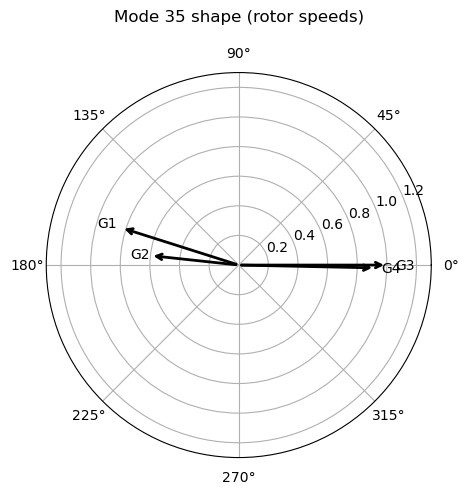

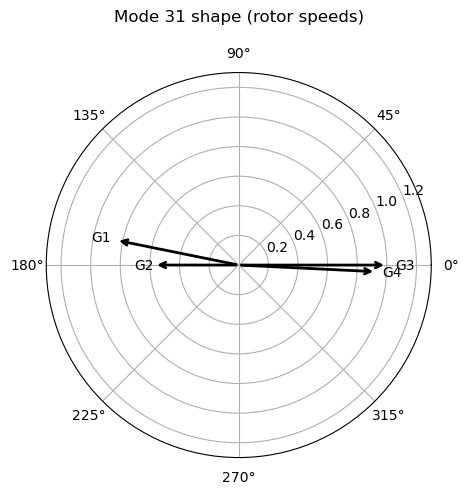

In [17]:
res_pss.mode_shape_plot(ia_pss.rows[0])       # PSS in service
res_nopss.mode_shape_plot(ia_nopss.rows[0]);  # PSS disabled

This is the definition of an inter-area mode, drawn. **G1 and G2 point one way, G3 and G4
point the other, close to 180 degrees apart**: area 1 swings against area 2, and the two
machines within each area move together. That is why taking $\delta_{G1} - \delta_{G3}$ in
Part 1 isolated this mode so cleanly, and why the common drift cancelled: the difference
across the tie is precisely the coordinate this mode moves along.

Both panels show the same picture, which is the point. The stabiliser changed the damping
of this mode by a factor of five and flipped its sign, without meaningfully changing
either its frequency or which machines it moves. It damps the oscillation; it does not
rearrange it.

Compare this with the local modes: call `res_nopss.mode_shape(mode)` for the 1.08 Hz mode
and only G1 and G2 have any length, because a local mode is one machine swinging against
its neighbour inside one area, and the other area barely knows about it.
`res_nopss.participation(mode)` says the same thing per state rather than per machine.

## What you have seen

- A RAMSES case assembled from four files and run twice, with **one parameter changed**
  between the runs, which is the cleanest way to attribute an effect to a control.
- The **inter-area mode** of the two-area system, near 0.62 Hz, separated from the faster
  local mode by taking angle differences across the areas rather than absolute angles.
- The PSS doing its job: with $K_{STAB} = 20$ the mode is damped; with $K_{STAB} = 0$ the
  same disturbance drives it unstable and the machines pull out of step.
- A **monitoring DCTL stopping a run on purpose**. `SIM_MINMAXVOLT` firing is a result to
  report, not an error to work around, and the trajectory written up to that point is
  complete and usable.
- The **same conclusion reached twice**, once by fitting an envelope to a time response and
  once by asking for the eigenvalues directly. They agree, and the second needed no
  disturbance, returned every mode rather than the excited one, and settled stability by
  the sign of $\text{Re}(\lambda)$ rather than by watching machines pull out of step.
- The **mode shape** identifying the oscillation as area 1 against area 2, which is what
  justifies reading it off $\delta_{G1} - \delta_{G3}$ in the first place.

### Things to try

- **Find the stability boundary.** Copy `dyn_noPSS.dat` and sweep $K_{STAB}$ (say 0, 2, 5,
  10, 20) on all four machines, re-running each time and recording the damping ratio from
  `mode_estimate`. At what gain does the mode cross into the left half-plane?
- **Sweep the gain against the eigenvalue.** Part 3 gives the damping ratio in one short
  run, so the sweep above no longer needs a 60-second simulation per point: call
  `run_ssa(dyn_file, workdir)` for each `KSTAB`, filter with
  `.electromechanical().dominant(-3.0)`, and read off the inter-area row's zeta. The
  crossing is where it meets zero.
- **Change what excites the mode.** Replace the load step with a line trip
  (`BREAKER BRANCH 7-8#1 0 0`) to remove one of the two tie circuits, weakening the
  corridor and moving the mode.
- **Look at the PSS acting.** `ext_pss.getExc('G1')` exposes the exciter states, so you can
  plot the stabilizer's contribution to the field voltage against the speed deviation it
  is derived from.

### References

- P. Kundur, *Power System Stability and Control*, McGraw-Hill, 1994, Example 12.6.
- stepss documentation: <https://stepss.sps-lab.org/python/>
- STEPSS simulation guide: <https://stepss.sps-lab.org/user-guide/file-formats/>, and the
  [`exc_kundur` model](https://stepss.sps-lab.org/models/custom-exciters/)